In [4]:
# !pip install pytorchvideo transformers evaluate -q

In [5]:
# !pip install ipywidgets

In [6]:
# from huggingface_hub import notebook_login

# notebook_login()

In [1]:
import pathlib

dataset_root_path = pathlib.Path("/work/long_lab/Mojtaba/data/UTA/1.4-augmentated_masked_cropped_split1")
video_count_train = len(list(dataset_root_path.glob("train/*/*.mp4")))
video_count_val = len(list(dataset_root_path.glob("val/*/*.mp4")))
video_count_test = len(list(dataset_root_path.glob("test/*/*.mp4")))
video_total = video_count_train + video_count_val + video_count_test
print(f"Total videos: {video_total}")

Total videos: 175


In [2]:
video_count_train, video_count_val, video_count_test

(103, 36, 36)

In [3]:
all_video_file_paths = (
    list(dataset_root_path.glob("train/*/*.mp4"))
    + list(dataset_root_path.glob("val/*/*.mp4"))
    + list(dataset_root_path.glob("test/*/*.mp4"))
)
all_video_file_paths[:5]

[PosixPath('/work/long_lab/Mojtaba/data/UTA/1.4-augmentated_masked_cropped_split1/train/0/3_26_0_30fps_cropped.mp4'),
 PosixPath('/work/long_lab/Mojtaba/data/UTA/1.4-augmentated_masked_cropped_split1/train/0/3_29_0_30fps_cropped.mp4'),
 PosixPath('/work/long_lab/Mojtaba/data/UTA/1.4-augmentated_masked_cropped_split1/train/0/3_30_0_30fps_cropped.mp4'),
 PosixPath('/work/long_lab/Mojtaba/data/UTA/1.4-augmentated_masked_cropped_split1/train/0/3_25_0_30fps_cropped.mp4'),
 PosixPath('/work/long_lab/Mojtaba/data/UTA/1.4-augmentated_masked_cropped_split1/train/0/3_31_0_30fps_cropped.mp4')]

In [4]:
class_labels = sorted({str(path).split("/")[8] for path in all_video_file_paths})
label2id = {label: i for i, label in enumerate(class_labels)}
id2label = {i: label for label, i in label2id.items()}

print(f"Unique classes: {list(label2id.keys())}.")

Unique classes: ['0', '10', '5'].


In [5]:
from transformers import VideoMAEImageProcessor, VideoMAEForVideoClassification

model_ckpt = "MCG-NJU/videomae-base" # pre-trained model from which to fine-tune
batch_size = 16 # batch size for training and evaluation

image_processor = VideoMAEImageProcessor.from_pretrained(model_ckpt)
model = VideoMAEForVideoClassification.from_pretrained(
    model_ckpt,
    label2id=label2id,
    id2label=id2label,
    ignore_mismatched_sizes=True,  # provide this in case you're planning to fine-tune an already fine-tuned checkpoint
)

2025-06-04 11:24:05.696891: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-06-04 11:24:05.769321: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1749057845.897384 3016490 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1749057845.911233 3016490 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1749057846.007838 3016490 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking 

In [6]:
import pytorchvideo

from pytorchvideo.data.labeled_video_dataset import labeled_video_dataset

from pytorchvideo.transforms import (
    ApplyTransformToKey,
    Normalize,
    RandomShortSideScale,
    RemoveKey,
    ShortSideScale,
    UniformTemporalSubsample,
)

from torchvision.transforms import (
    Compose,
    Lambda,
    RandomCrop,
    RandomHorizontalFlip,
    Resize,
)

In [7]:
image_processor

VideoMAEImageProcessor {
  "crop_size": {
    "height": 224,
    "width": 224
  },
  "do_center_crop": true,
  "do_normalize": true,
  "do_rescale": true,
  "do_resize": true,
  "image_mean": [
    0.485,
    0.456,
    0.406
  ],
  "image_processor_type": "VideoMAEImageProcessor",
  "image_std": [
    0.229,
    0.224,
    0.225
  ],
  "resample": 2,
  "rescale_factor": 0.00392156862745098,
  "size": {
    "shortest_edge": 224
  }
}

In [27]:
model.config.num_frames = 16

In [29]:
import os

mean = image_processor.image_mean
std = image_processor.image_std
if "shortest_edge" in image_processor.size:
    height = width = image_processor.size["shortest_edge"]
else:
    height = image_processor.size["height"]
    width = image_processor.size["width"]
resize_to = (height, width)

num_frames_to_sample = model.config.num_frames
sample_rate = 3
fps = 30
clip_duration = num_frames_to_sample * sample_rate / fps


# Training dataset transformations.
train_transform = Compose(
    [
        ApplyTransformToKey(
            key="video",
            transform=Compose(
                [
                    UniformTemporalSubsample(num_frames_to_sample),
                    Lambda(lambda x: x / 255.0),
                    Normalize(mean, std),
                    Resize(resize_to),
                ]
            ),
        ),
    ]
)

# Validation and evaluation datasets' transformations.
val_transform = Compose(
    [
        ApplyTransformToKey(
            key="video",
            transform=Compose(
                [
                    UniformTemporalSubsample(num_frames_to_sample),
                    Lambda(lambda x: x / 255.0),
                    Normalize(mean, std),
                    Resize(resize_to),
                ]
            ),
        ),
    ]
)

In [54]:
from pytorchvideo.data.clip_sampling import ConstantClipsPerVideoSampler

In [55]:
# Training dataset.
num_clips = 10
train_dataset = labeled_video_dataset(
    data_path=os.path.join(dataset_root_path, "train"),
    clip_sampler=ConstantClipsPerVideoSampler(clip_duration=clip_duration, clips_per_video=num_clips),
    decode_audio=False,
    transform=train_transform,
)

In [56]:
# Validation and evaluation datasets.
val_dataset = labeled_video_dataset(
    data_path=os.path.join(dataset_root_path, "val"),
    clip_sampler=ConstantClipsPerVideoSampler(clip_duration=clip_duration, clips_per_video=num_clips),
    decode_audio=False,
    transform=val_transform,
)

In [57]:
test_dataset = labeled_video_dataset(
    data_path=os.path.join(dataset_root_path, "test"),
    clip_sampler=ConstantClipsPerVideoSampler(clip_duration=clip_duration, clips_per_video=num_clips),
    decode_audio=False,
    transform=val_transform,
)

In [58]:
# We can access the `num_videos` argument to know the number of videos we have in the
# dataset.
train_dataset.num_videos, val_dataset.num_videos, test_dataset.num_videos

(103, 36, 36)

In [59]:
# sample_video = next(iter(train_dataset))
# sample_video.keys()

In [60]:
def investigate_video(sample_video):
    """Utility to investigate the keys present in a single video sample."""
    for k in sample_video:
        if k == "video":
            print(k, sample_video["video"].shape)
        else:
            print(k, sample_video[k])

    print(f"Video label: {id2label[sample_video[k]]}")

In [61]:
# !pip install imageio

In [62]:
import imageio
import numpy as np
from IPython.display import Image


def unnormalize_img(img):
    """Un-normalizes the image pixels."""
    img = (img * std) + mean
    img = (img * 255).astype("uint8")
    return img.clip(0, 255)


def create_gif(video_tensor, filename="sample.gif"):
    """Prepares a GIF from a video tensor.
    
    The video tensor is expected to have the following shape:
    (num_frames, num_channels, height, width).
    """
    frames = []
    for video_frame in video_tensor:
        frame_unnormalized = unnormalize_img(video_frame.permute(1, 2, 0).numpy())
        frames.append(frame_unnormalized)
    kargs = {"duration": 0.25}
    imageio.mimsave(filename, frames, "GIF", **kargs)
    return filename


def display_gif(video_tensor, gif_name="sample.gif"):
    """Prepares and displays a GIF from a video tensor."""
    video_tensor = video_tensor.permute(1, 0, 2, 3)
    gif_filename = create_gif(video_tensor, gif_name)
    return Image(filename=gif_filename)

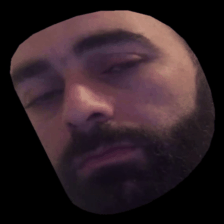

In [63]:
video_tensor = sample_video["video"]
display_gif(video_tensor)

In [ ]:
from transformers import TrainingArguments, Trainer

model_name = model_ckpt.split("/")[-1]
new_model_name = f"{model_name}-finetuned-fatigue-subset-2"
num_epochs = 5

args = TrainingArguments(
    new_model_name,
    remove_unused_columns=False,
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=5e-5,
    per_device_train_batch_size=batch_size,
    per_device_eval_batch_size=batch_size,
    warmup_ratio=0.1,
    logging_steps=10,
    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
    push_to_hub=False,
    max_steps=(train_dataset.num_videos*num_clips // batch_size) * num_epochs,
)

In [88]:
import evaluate

metric = evaluate.load("accuracy")

In [89]:
# the compute_metrics function takes a Named Tuple as input:
# predictions, which are the logits of the model as Numpy arrays,
# and label_ids, which are the ground-truth labels as Numpy arrays.
def compute_metrics(eval_pred):
    """Computes accuracy on a batch of predictions."""
    predictions = np.argmax(eval_pred.predictions, axis=1)
    return metric.compute(predictions=predictions, references=eval_pred.label_ids)

In [90]:
import torch


def collate_fn(examples):
    """The collation function to be used by `Trainer` to prepare data batches."""
    # permute to (num_frames, num_channels, height, width)
    pixel_values = torch.stack(
        [example["video"].permute(1, 0, 2, 3) for example in examples]
    )
    labels = torch.tensor([example["label"] for example in examples])
    return {"pixel_values": pixel_values, "labels": labels}

In [91]:
trainer = Trainer(
    model,
    args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    tokenizer=image_processor,
    compute_metrics=compute_metrics,
    data_collator=collate_fn,
)

/tmp/ipykernel_3016490/3087471478.py:1: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(
Detected kernel version 4.18.0, which is below the recommended minimum of 5.5.0; this can cause the process to hang. It is recommended to upgrade the kernel to the minimum version or higher.


In [92]:
train_results = trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy
0,1.291600,1.264737,0.333333
1,1.030200,1.141161,0.333333
2,1.096000,1.100355,0.333333
3,1.091000,1.104499,0.291667


ResourceExhaustedError: videomae-base-finetuned-fatigue-subset-2/runs/Jun04_12-23-49_mmg1/events.out.tfevents.1749061451.mmg1.3016490.6; Disk quota exceeded

In [ ]:
trainer.evaluate(test_dataset)

In [ ]:
trainer.save_model()
test_results = trainer.evaluate(test_dataset)
trainer.log_metrics("test", test_results)
trainer.save_metrics("test", test_results)
trainer.save_state()